<a href="https://colab.research.google.com/github/zome666/UNLOX-Cars-EDA-Minor-Project/blob/main/Cars_EDA_UNLOX_Minor_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [ ]:
url = 'https://raw.githubusercontent.com/aman-mnnit28/car-price-analysis/main/Car_Sell_Dataset.csv'
df = pd.read_csv(url)

print('Dataset loaded successfully!')
print('Shape:', df.shape)
df.head()

Dataset loaded successfully!
Shape: (140904, 12)


,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
0,Mahindra,TUV300,AX5,SUV,Manual,CNG,2017,164654,1st,Rajasthan,No,547253
1,Skoda,Rapid,Style,Sedan,Manual,Petrol,2018,41351,1st,Maharashtra,No,512050
2,Maruti Suzuki,Alto,Z,Hatchback,Manual,Diesel,2002,119090,3rd+,Tamil Nadu,No,678923
3,Hyundai,Grand i10,Magna,Hatchback,Manual,Diesel,2013,19979,1st,Andhra Pradesh,No,522500
4,Mahindra,XUV500,W8,SUV,Manual,Petrol,2011,130591,3rd+,Bihar,No,401182


In [ ]:
print('Rows and columns:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nData types:')
print(df.dtypes)
print('\nFirst five rows:')
display(df.head())

Rows and columns: (140904, 12)

Column names:
['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission', 'Fuel Type', 'Year', 'Kilometers', 'Owner', 'State', 'Accidental', 'Price']

Data types:
Brand            object
Model Name       object
Model Variant    object
Car Type         object
Transmission     object
Fuel Type        object
Year              int64
Kilometers        int64
Owner            object
State            object
Accidental       object
Price             int64
dtype: object

First five rows:


,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
0,Mahindra,TUV300,AX5,SUV,Manual,CNG,2017,164654,1st,Rajasthan,No,547253
1,Skoda,Rapid,Style,Sedan,Manual,Petrol,2018,41351,1st,Maharashtra,No,512050
2,Maruti Suzuki,Alto,Z,Hatchback,Manual,Diesel,2002,119090,3rd+,Tamil Nadu,No,678923
3,Hyundai,Grand i10,Magna,Hatchback,Manual,Diesel,2013,19979,1st,Andhra Pradesh,No,522500
4,Mahindra,XUV500,W8,SUV,Manual,Petrol,2011,130591,3rd+,Bihar,No,401182


In [ ]:
print('Missing values:')
display(df.isnull().sum().to_frame('Missing Values'))

print('Number of duplicate rows:', df.duplicated().sum())

Missing values:


,Missing Values
Brand,0
Model Name,0
Model Variant,0
Car Type,0
Transmission,0
Fuel Type,0
Year,0
Kilometers,0
Owner,0
State,0


Number of duplicate rows: 0


In [ ]:
before_cleaning = len(df)

# Standardise column names
df.columns = (df.columns.str.strip().str.lower()
             .str.replace(' ', '_')
             .str.replace(r'[^a-z0-9_]', '', regex=True))

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert important numerical columns
for col in ['year', 'kilometers', 'price']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Clean text categories
for col in ['brand', 'model_name', 'model_variant', 'car_type',
            'transmission', 'fuel_type', 'owner', 'state', 'accidental']:
    if col in df.columns:
        df[col] = df[col].astype('string').str.strip()

# Remove impossible basic values
if 'year' in df.columns:
    df = df[df['year'].between(1990, 2026)]
if 'kilometers' in df.columns:
    df = df[df['kilometers'] >= 0]
if 'price' in df.columns:
    df = df[df['price'] > 0]

# New useful features
df['vehicle_age'] = 2026 - df['year']
df['price_lakh'] = df['price'] / 100000

after_cleaning = len(df)

print('Rows before cleaning:', before_cleaning)
print('Rows after cleaning:', after_cleaning)
print('Rows removed:', before_cleaning - after_cleaning)

Rows before cleaning: 140904
Rows after cleaning: 140904
Rows removed: 0


In [ ]:
print('Numerical descriptive statistics:')
display(df.select_dtypes(include=np.number).describe().round(2))

Numerical descriptive statistics:


,year,kilometers,price,vehicle_age,price_lakh
count,140904.00,140904.00,140904.00,140904.00,140904.00
mean,2016.96,95024.60,761787.17,9.04,7.62
std,5.11,49133.16,443857.75,5.11,4.44
min,2000.00,10000.00,50055.00,3.00,0.50
25%,2014.00,52421.00,411642.00,5.00,4.12
50%,2018.00,94973.50,682803.00,8.00,6.83
75%,2021.00,137618.00,1034178.25,12.00,10.34
max,2023.00,179998.00,2744280.00,26.00,27.44


In [ ]:
print('Categorical variable summaries:')
for col in ['brand', 'car_type', 'fuel_type', 'transmission', 'owner']:
    if col in df.columns:
        print(f'\n--- {col.upper()} ---')
        display(df[col].value_counts().head(10).to_frame('Count'))

Categorical variable summaries:

--- BRAND ---


,Count
brand,
Maruti Suzuki,54030
Hyundai,22090
Honda,11936
Toyota,10483
Mahindra,9618
Tata,8825
Ford,5217
Volkswagen,3716
Renault,3024



--- CAR_TYPE ---


,Count
car_type,
Hatchback,55890
Sedan,36897
SUV,35057
MPV,9702
Luxury,3358



--- FUEL_TYPE ---


,Count
fuel_type,
Petrol,79187
Diesel,42038
CNG,14054
Electric,2853
Hybrid,2772



--- TRANSMISSION ---


,Count
transmission,
Manual,119793
Automatic,21111



--- OWNER ---


,Count
owner,
1st,75429
2nd,56492
3rd+,8983


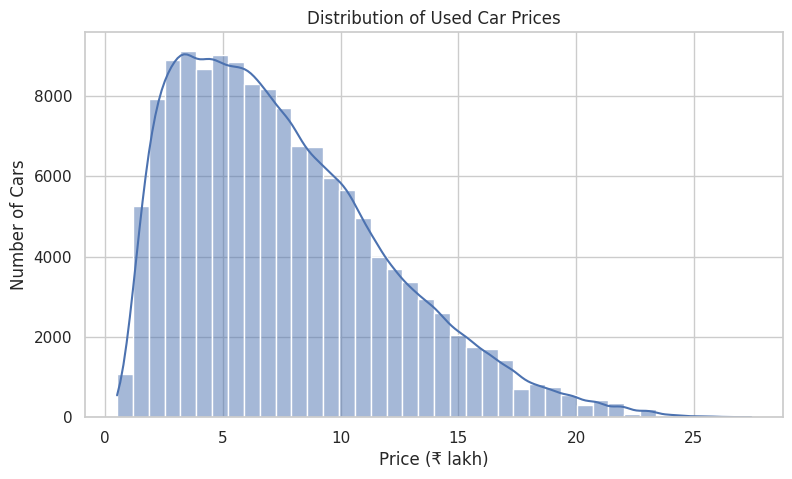

In [ ]:
plt.figure(figsize=(9,5))
sns.histplot(df['price_lakh'], bins=40, kde=True)
plt.title('Distribution of Used Car Prices')
plt.xlabel('Price (₹ lakh)')
plt.ylabel('Number of Cars')
plt.show()

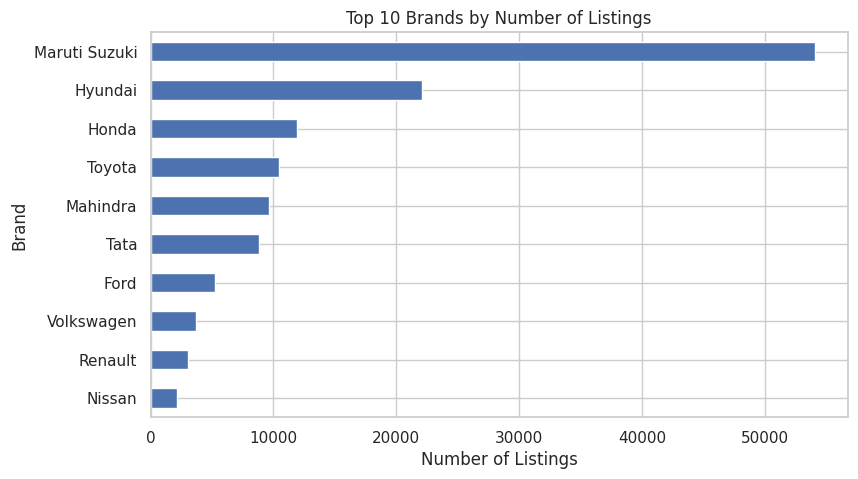

In [ ]:
plt.figure(figsize=(9,5))
df['brand'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Brands by Number of Listings')
plt.xlabel('Number of Listings')
plt.ylabel('Brand')
plt.show()

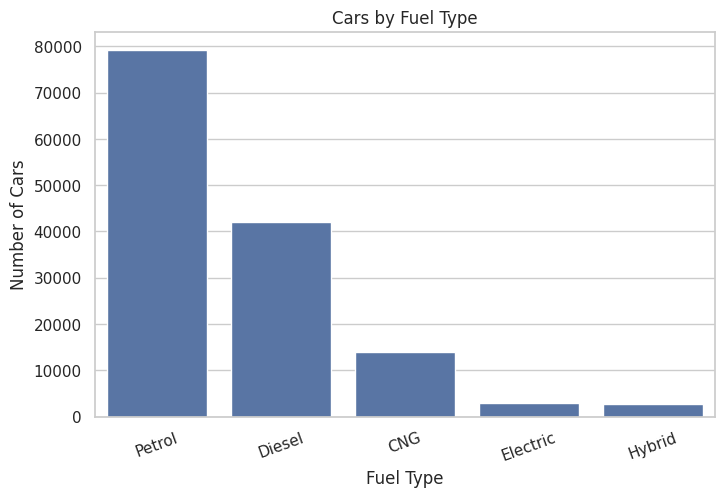

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='fuel_type', order=df['fuel_type'].value_counts().index)
plt.title('Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.xticks(rotation=20)
plt.show()

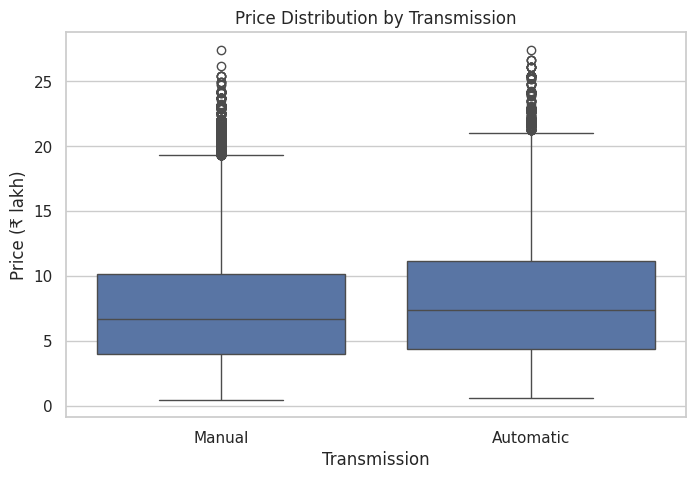

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='transmission', y='price_lakh')
plt.title('Price Distribution by Transmission')
plt.xlabel('Transmission')
plt.ylabel('Price (₹ lakh)')
plt.show()

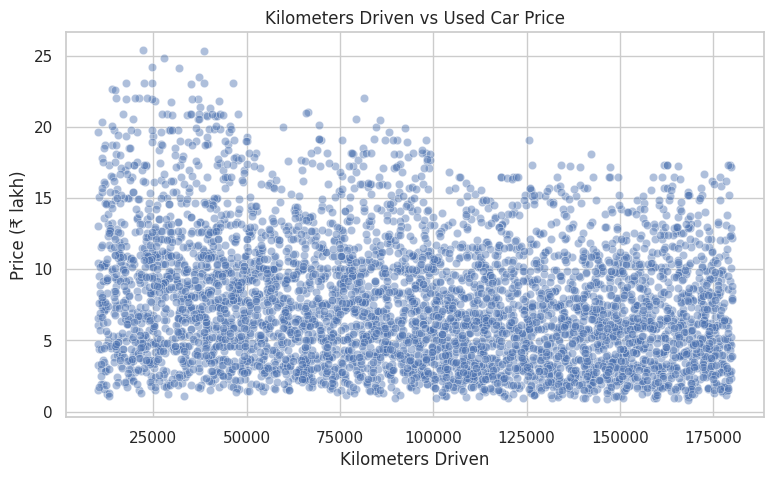

In [ ]:
sample = df.sample(min(5000, len(df)), random_state=42)
plt.figure(figsize=(9,5))
sns.scatterplot(data=sample, x='kilometers', y='price_lakh', alpha=0.45)
plt.title('Kilometers Driven vs Used Car Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Price (₹ lakh)')
plt.show()

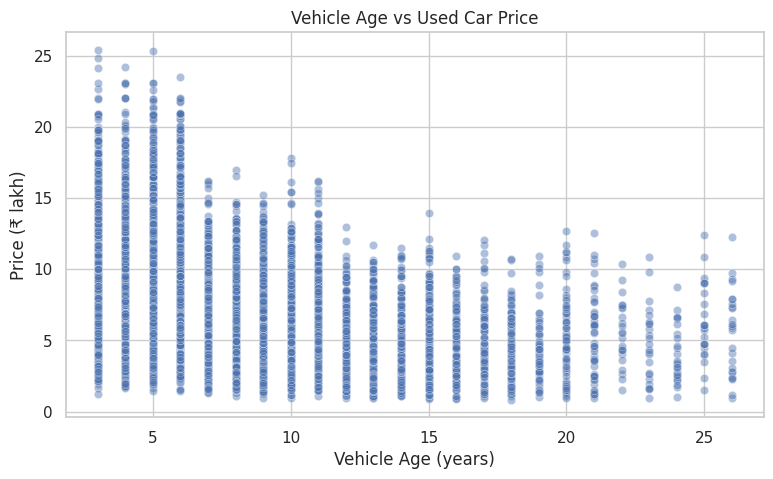

In [ ]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=sample, x='vehicle_age', y='price_lakh', alpha=0.45)
plt.title('Vehicle Age vs Used Car Price')
plt.xlabel('Vehicle Age (years)')
plt.ylabel('Price (₹ lakh)')
plt.show()

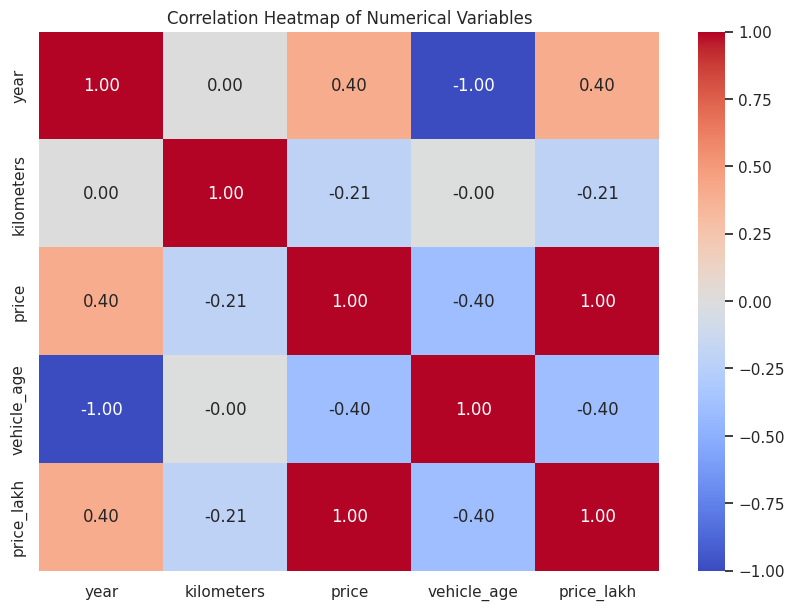

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(10,7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

In [ ]:
q1 = df['price_lakh'].quantile(0.25)
q3 = df['price_lakh'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[(df['price_lakh'] < lower) | (df['price_lakh'] > upper)]

print('Lower bound:', round(lower, 2), 'lakh')
print('Upper bound:', round(upper, 2), 'lakh')
print('Number of price outliers:', len(outliers))

Lower bound: -5.22 lakh
Upper bound: 19.68 lakh
Number of price outliers: 1820
